# Bilevel poisoning of logistic regression in secml-torch

This notebook ports the gradient-based poisoning attack against logistic regression
from `secml` (`CAttackPoisoningLogisticRegression`) to PyTorch / secml-torch.

**Contents**
1. The bilevel problem and the hypergradient for logistic regression
2. Numerical check of the hypergradient (closed form vs. autograd vs. finite differences)
3. 2D examples: attacker-loss landscape, hypergradient field, attack trajectories
4. MNIST digits (4 vs 0)

References: Biggio et al., *Poisoning attacks against SVMs*, ICML 2012;
Mei & Zhu, AAAI 2015; Muñoz-González et al., AISec 2017;
Demontis et al., *Why do adversarial attacks transfer?*, USENIX Security 2019 (Sect. 3.3).

## 1. Bilevel problem and hypergradient

The attacker adds poisoning points $\mathcal D_p=\{(\mathbf x_c, y_c)\}_{c=1}^m$ (labels fixed, features optimized)
to maximize a loss $\mathcal A$ on its validation set $\mathcal D_{val}$:

$$
\max_{\mathbf x_c \in [\mathbf{lb},\mathbf{ub}]} \; \mathcal A(\boldsymbol\theta^\star)=\frac{1}{|\mathcal D_{val}|}\sum_{k\in\mathcal D_{val}} \ell(y_k, f(\mathbf x_k;\boldsymbol\theta^\star))
\quad\text{s.t.}\quad
\boldsymbol\theta^\star \in \arg\min_{\boldsymbol\theta} \mathcal L(\boldsymbol\theta;\, \mathcal D_{tr}\cup\mathcal D_p).
$$

For logistic regression, $\boldsymbol\theta=(\mathbf w,b)$, $y\in\{-1,+1\}$, and

$$
\mathcal L = \tfrac12\|\mathbf w\|^2 + C\sum_i \log\!\big(1+e^{-y_i(\mathbf w^\top\mathbf x_i+b)}\big).
$$

**Implicit differentiation.** At the inner optimum $\nabla_{\boldsymbol\theta}\mathcal L(\boldsymbol\theta^\star,\mathbf x_c)=\mathbf 0$.
Differentiating this identity w.r.t. $\mathbf x_c$ gives
$\frac{\partial\boldsymbol\theta^\star}{\partial\mathbf x_c} = -\mathbf H^{-1}\mathbf G_c^\top$, hence

$$
\nabla_{\mathbf x_c}\mathcal A = -\,\mathbf G_c\,\mathbf H^{-1}\nabla_{\boldsymbol\theta}\mathcal A,
\qquad
\mathbf H=\nabla^2_{\boldsymbol\theta}\mathcal L,\quad
\mathbf G_c=\frac{\partial^2\mathcal L}{\partial\mathbf x_c\,\partial\boldsymbol\theta^\top}\in\mathbb R^{d\times(d+1)}.
$$

**Closed form for LR.** Let $s_i=\mathbf w^\top\mathbf x_i+b$, $\sigma_i=\mathrm{sigm}(y_i s_i)$, $z_i=\sigma_i(1-\sigma_i)$, $\tilde{\mathbf x}_i=[\mathbf x_i;1]$.

* Gradient of the training loss: $\nabla_{\mathbf w}\mathcal L=\mathbf w - C\sum_i y_i(1-\sigma_i)\mathbf x_i$, $\;\nabla_b\mathcal L=-C\sum_i y_i(1-\sigma_i)$.
* Hessian (bias not regularized): $\mathbf H=\begin{bmatrix}\mathbf I&\mathbf 0\\\mathbf 0&0\end{bmatrix}+C\sum_i z_i\,\tilde{\mathbf x}_i\tilde{\mathbf x}_i^\top$.
* Mixed derivative (only the term of point $c$ depends on $\mathbf x_c$; use $\partial\sigma_c/\partial\mathbf x_c = z_c\,y_c\,\mathbf w$ and $y_c^2=1$):
  $$\mathbf G_c = C\big[-y_c(1-\sigma_c)\,[\mathbf I\;\;\mathbf 0] + z_c\,\mathbf w\,\tilde{\mathbf x}_c^\top\big].$$
* Validation gradient, with $\ell$ the logistic loss: $\nabla_{\boldsymbol\theta}\mathcal A=\frac1{n_{val}}\sum_k -y_k(1-\sigma_k)\tilde{\mathbf x}_k$.

Solving **one** linear system $\mathbf v=[\mathbf v_w; v_b]=\mathbf H^{-1}\nabla_{\boldsymbol\theta}\mathcal A$ (shared by all poisoning points) gives

$$
\boxed{\;\nabla_{\mathbf x_c}\mathcal A = C\Big[\,y_c(1-\sigma_c)\,\mathbf v_w \;-\; z_c\,(\mathbf x_c^\top\mathbf v_w+v_b)\,\mathbf w\Big]\;}
$$

This is the same quantity as `_gradient_fk_xc` in secml, without forming $\mathbf H^{-1}$ or $\mathbf G_c$.
Intuition: the first term moves $\mathbf x_c$ along the direction in which the *weights* should change to hurt
validation performance; the second term (along $\mathbf w$) controls how much "leverage" the point has, through its margin.

The generic version `implicit_hypergradient` computes $-\partial_{\mathbf x_c}\big(\mathbf v^\top\nabla_{\boldsymbol\theta}\mathcal L\big)$
with autograd for any twice-differentiable learner — handy to verify closed forms and for future learners.

In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import make_blobs

from secmlt_poisoning import (
    BilevelPoisoningLogisticRegression,
    LogisticRegression,
    fit_logistic_regression,
    logistic_hypergradient,
)
from secmlt_poisoning.hypergradient import mean_logistic_loss

torch.set_default_dtype(torch.float64)
# Figure style of Biggio et al., ICML 2012 (original MATLAB code): default `jet` colormap,
# red/blue class dots, black SV circles, black boundary, dotted margins, black attack paths.
CMAP = "jet"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})


def accuracy(model, x, y):
    return (model.score(x).detach() > 0).long().eq(y).double().mean().item()

## 2. Checking the hypergradient

In [2]:
X, Y = make_blobs(1300, centers=[[-1, -1], [1, 1]], cluster_std=0.9, random_state=0)
X, Y = torch.tensor(X), torch.tensor(Y)
x_tr, y_tr = X[:100], Y[:100]
x_val, y_val = X[100:300], Y[100:300]
x_ts, y_ts = X[300:], Y[300:]
C = 1.0

x_p, y_p = x_tr[:3] + 0.1, 1 - y_tr[:3]  # 3 poisoning points with flipped labels


def val_loss(xp):
    w, b = fit_logistic_regression(torch.cat([x_tr, xp]), torch.cat([y_tr, y_p]), C=C)
    return mean_logistic_loss(x_val @ w + b, 2.0 * y_val - 1).item()


w, b = fit_logistic_regression(torch.cat([x_tr, x_p]), torch.cat([y_tr, y_p]), C=C)
g_closed, _ = logistic_hypergradient(w, b, x_tr, y_tr, x_p, y_p, x_val, y_val, C)
g_auto, _ = BilevelPoisoningLogisticRegression(C=C, hypergradient="autograd").gradient(
    x_tr, y_tr, x_p, y_p, x_val, y_val)

eps, g_fd = 1e-4, torch.zeros_like(x_p)
for i in range(x_p.shape[0]):
    for j in range(x_p.shape[1]):
        e = torch.zeros_like(x_p); e[i, j] = eps
        g_fd[i, j] = (val_loss(x_p + e) - val_loss(x_p - e)) / (2 * eps)

print("closed form :\n", g_closed)
print("autograd    :\n", g_auto)
print("finite diff.:\n", g_fd)
print("max |closed - autograd| =", (g_closed - g_auto).abs().max().item())
print("max |closed - fin.diff| =", (g_closed - g_fd).abs().max().item())

closed form :
 tensor([[ 0.0083,  0.0020],
        [ 0.0084,  0.0021],
        [-0.0063, -0.0019]])
autograd    :
 tensor([[ 0.0083,  0.0020],
        [ 0.0084,  0.0021],
        [-0.0063, -0.0019]])
finite diff.:
 tensor([[ 0.0083,  0.0020],
        [ 0.0084,  0.0021],
        [-0.0063, -0.0019]])
max |closed - autograd| = 6.938893903907228e-18
max |closed - fin.diff| = 4.568708258934073e-12


## 3. 2D examples

Two Gaussian blobs; 100 training points, 200 validation points (attacker), 1000 test points.

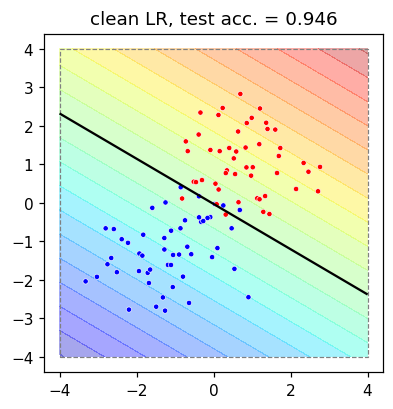

In [3]:
lb, ub = -4.0, 4.0
grid_n = 60
gx, gy = np.meshgrid(np.linspace(lb, ub, grid_n), np.linspace(lb, ub, grid_n))
grid = torch.tensor(np.c_[gx.ravel(), gy.ravel()])
COL = np.array(["b", "r"])


def plot_clf(ax, model, title=None, levels=True):
    f = model.score(grid).detach().numpy().reshape(gx.shape)
    if levels:
        ax.contourf(gx, gy, f, levels=20, cmap=CMAP, alpha=0.35)
    ax.contour(gx, gy, f, levels=[0], colors="k", linewidths=1.5)
    ax.scatter(*x_tr.T, c=COL[y_tr], s=12, edgecolors="w", linewidths=0.4)
    ax.add_patch(plt.Rectangle((lb, lb), ub - lb, ub - lb, fill=False, ls="--", lw=0.8, ec="gray"))
    ax.set_xlim(lb - 0.4, ub + 0.4); ax.set_ylim(lb - 0.4, ub + 0.4); ax.set_aspect("equal")
    if title: ax.set_title(title)


clean = LogisticRegression(2, C=C).fit(x_tr, y_tr)
fig, ax = plt.subplots(figsize=(4, 4))
plot_clf(ax, clean, f"clean LR, test acc. = {accuracy(clean, x_ts, y_ts):.3f}")

### Attacker-loss landscape for a single poisoning point

For every location $\mathbf x_c$ on a grid we retrain the classifier on $\mathcal D_{tr}\cup\{(\mathbf x_c,y_c)\}$ and
evaluate $\mathcal A$ on the validation set (this is what the bilevel problem optimizes, computed by brute force).
Arrows show the (normalized) hypergradient $\nabla_{\mathbf x_c}\mathcal A$: they should point uphill.
The red/blue color of the title is the label $y_c$ of the poisoning point.

7200 retrainings + 392 hypergradients in 2.0s


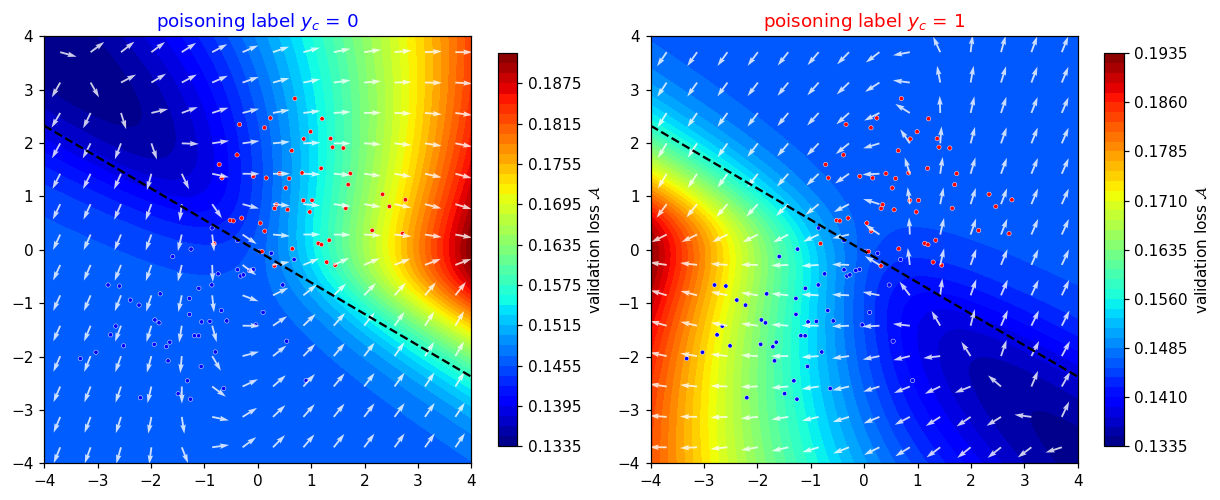

In [4]:
attack = BilevelPoisoningLogisticRegression(C=C, lb=lb, ub=ub)
q = np.linspace(lb + 0.3, ub - 0.3, 14)
qx, qy = np.meshgrid(q, q)
qgrid = torch.tensor(np.c_[qx.ravel(), qy.ravel()])

landscape = {}
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
t0 = time.time()
for ax, yc in zip(axs, [0, 1]):
    ycs = torch.tensor([yc])
    A = np.array([attack.objective(x_tr, y_tr, xc[None], ycs, x_val, y_val).item() for xc in grid])
    landscape[yc] = A.reshape(gx.shape)
    G = np.stack([attack.gradient(x_tr, y_tr, xc[None], ycs, x_val, y_val)[0][0].numpy() for xc in qgrid])
    G /= np.linalg.norm(G, axis=1, keepdims=True) + 1e-12
    cs = ax.contourf(gx, gy, landscape[yc], levels=50, cmap=CMAP)
    plt.colorbar(cs, ax=ax, fraction=0.046, label="validation loss $\\mathcal{A}$")
    ax.contour(gx, gy, clean.score(grid).detach().numpy().reshape(gx.shape), levels=[0], colors="k", linestyles="--")
    ax.scatter(*x_tr.T, c=COL[y_tr], s=8, edgecolors="w", linewidths=0.3)
    ax.quiver(qx, qy, G[:, 0].reshape(qx.shape), G[:, 1].reshape(qx.shape), color="w", alpha=0.8, scale=25)
    ax.set_title(f"poisoning label $y_c$ = {yc}", color=COL[yc]); ax.set_aspect("equal")
print(f"{2 * len(grid)} retrainings + {2 * len(qgrid)} hypergradients in {time.time() - t0:.1f}s")

The landscape is smooth and the hypergradient field is consistent with it. The best place for a point is far from its
own class, on the opposite side of the boundary, and as far as the box allows: the loss is highest near the corners
of the feasible domain. This is why the box constraint matters, and why poisoning points of a linear model end up on
the boundary of the feasible region.

### Single-point attack trajectories

Projected gradient ascent with line search from several starting points (labels flipped w.r.t. the class of the
starting point, as in secml's random initialization).

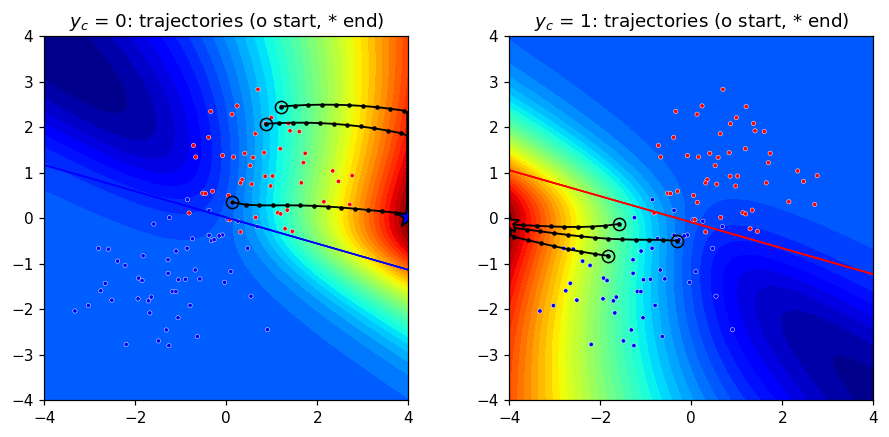

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.3))
starts = [x_tr[y_tr == 1][:3], x_tr[y_tr == 0][:3]]  # yc = 0 starts from class-1 points and vice versa
for ax, yc, x0s in zip(axs, [0, 1], starts):
    ax.contourf(gx, gy, landscape[yc], levels=50, cmap=CMAP)
    ax.scatter(*x_tr.T, c=COL[y_tr], s=8, edgecolors="w", linewidths=0.3)
    for x0 in x0s:
        att = BilevelPoisoningLogisticRegression(C=C, lb=lb, ub=ub, step_size=0.3, max_iter=100, store_path=True)
        res = att.run(x_tr, y_tr, x_val, y_val, x_init=x0[None], y_init=torch.tensor([yc]))
        path = torch.stack(res.history["x_poison"])[:, 0].numpy()
        ax.plot(*path.T, "k.-", lw=1.2, ms=4)
        ax.plot(*path[0], "o", mfc="none", mec="k", ms=8)
        ax.plot(*path[-1], "*", color=COL[yc], mec="k", ms=14)
        ax.contour(gx, gy, res.model.score(grid).detach().numpy().reshape(gx.shape), levels=[0], colors=COL[yc], linewidths=1)
    ax.set_title(f"$y_c$ = {yc}: trajectories (o start, * end)"); ax.set_aspect("equal")
    ax.set_xlim(lb, ub); ax.set_ylim(lb, ub)

### Multiple poisoning points

All points are updated jointly: $\mathbf v=\mathbf H^{-1}\nabla_{\boldsymbol\theta}\mathcal A$ is computed once per
iteration and shared by every point. Each point's gradient is normalized separately, so each point moves by at most
`step_size` per iteration. (secml optimized one point at a time, sweeping over the points.)

attack time 0.03s, 44 iterations
final poisoning points:
 [[ 4.  4.]
 [-4. -4.]
 [-4. -4.]
 [-4. -4.]
 [-4. -4.]
 [-4. -4.]
 [-4. -4.]
 [-4. -4.]
 [-4. -4.]
 [ 4.  4.]] 
labels: [0, 1, 1, 1, 1, 1, 1, 1, 1, 0]


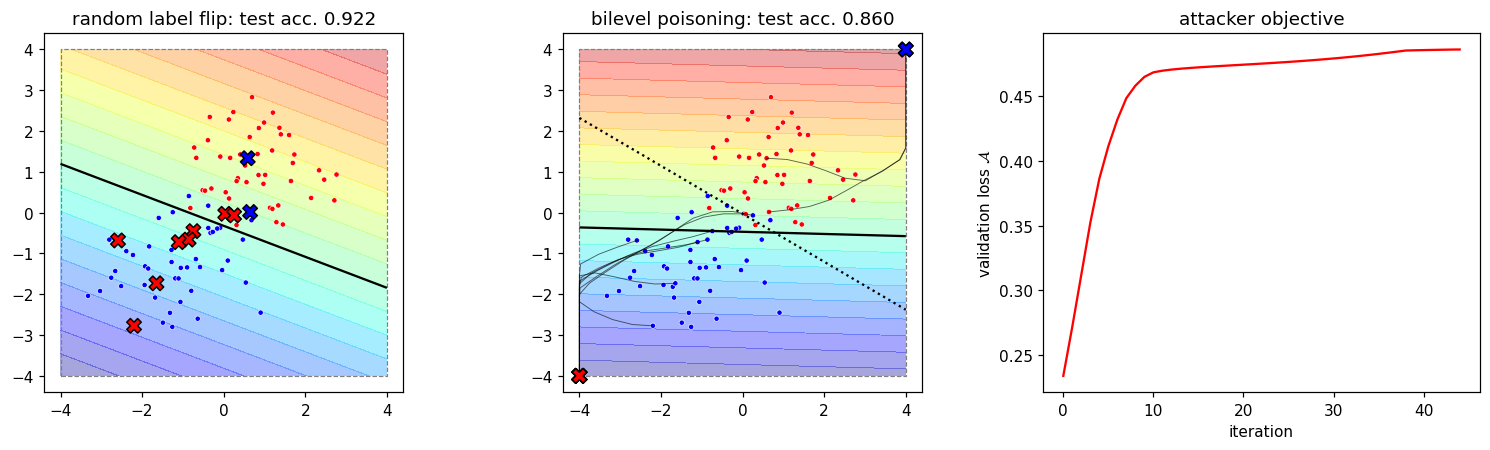

In [6]:
n_p = 10  # ~9% of the poisoned training set
attack = BilevelPoisoningLogisticRegression(C=C, lb=lb, ub=ub, step_size=0.5, max_iter=200,
                                            tol=1e-8, random_seed=0, store_path=True)
t0 = time.time()
res = attack.run(x_tr, y_tr, x_val, y_val, n_points=n_p)
print(f"attack time {time.time() - t0:.2f}s, {len(res.history['objective']) - 1} iterations")

x0 = res.history["x_poison"][0]
flip = LogisticRegression(2, C=C).fit(torch.cat([x_tr, x0]), torch.cat([y_tr, res.y_poison]))

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
plot_clf(axs[0], flip, f"random label flip: test acc. {accuracy(flip, x_ts, y_ts):.3f}")
axs[0].scatter(*x0.T, c=COL[res.y_poison], marker="X", s=90, edgecolors="k", clip_on=False, zorder=5)
plot_clf(axs[1], res.model, f"bilevel poisoning: test acc. {accuracy(res.model, x_ts, y_ts):.3f}")
paths = torch.stack(res.history["x_poison"]).numpy()
for i in range(n_p):
    axs[1].plot(*paths[:, i].T, "k-", lw=0.6, alpha=0.6)
axs[1].scatter(*res.x_poison.T, c=COL[res.y_poison], marker="X", s=90, edgecolors="k", clip_on=False, zorder=5)
axs[1].contour(gx, gy, clean.score(grid).detach().numpy().reshape(gx.shape), levels=[0], colors="k", linestyles=":")
axs[2].plot(res.history["objective"], "r-")
axs[2].set_xlabel("iteration"); axs[2].set_ylabel("validation loss $\\mathcal{A}$")
axs[2].set_title("attacker objective")
plt.tight_layout()
print("final poisoning points:\n", res.x_poison.numpy().round(2), "\nlabels:", res.y_poison.tolist())

Note how the optimized points collapse onto a few vertices of the feasible box: for a linear learner, the attacker
loss is maximized by points with maximal leverage, i.e. as far as possible from the bulk of the data. The box (here
$[-4,4]^2$) is therefore what bounds the attack's strength.

### Test accuracy vs. fraction of poisoning points (2D)

0.6s


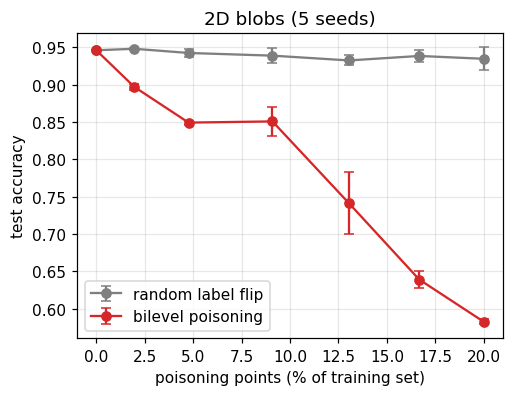

In [7]:
def curve(x_tr, y_tr, x_val, y_val, x_ts, y_ts, n_points, seeds, **attack_kw):
    acc_atk, acc_flip = np.zeros((len(seeds), len(n_points))), np.zeros((len(seeds), len(n_points)))
    for i, s in enumerate(seeds):
        for j, n in enumerate(n_points):
            if n == 0:
                m = LogisticRegression(x_tr[0].numel(), C=attack_kw["C"]).fit(x_tr, y_tr)
                acc_atk[i, j] = acc_flip[i, j] = accuracy(m, x_ts, y_ts)
                continue
            # max_iter=0 -> classifier trained on the random label-flip initialization
            r0 = BilevelPoisoningLogisticRegression(**{**attack_kw, "max_iter": 0}, random_seed=s).run(
                x_tr, y_tr, x_val, y_val, n_points=n)
            r = BilevelPoisoningLogisticRegression(**attack_kw, random_seed=s).run(
                x_tr, y_tr, x_val, y_val, n_points=n)
            acc_flip[i, j], acc_atk[i, j] = accuracy(r0.model, x_ts, y_ts), accuracy(r.model, x_ts, y_ts)
    return acc_atk, acc_flip


def plot_curve(ax, n_points, n_tr, acc_atk, acc_flip, title):
    frac = 100 * np.array(n_points) / (n_tr + np.array(n_points))
    for a, lab, c in [(acc_flip, "random label flip", "tab:gray"), (acc_atk, "bilevel poisoning", "tab:red")]:
        ax.errorbar(frac, a.mean(0), yerr=a.std(0), marker="o", label=lab, color=c, capsize=3)
    ax.set_xlabel("poisoning points (% of training set)"); ax.set_ylabel("test accuracy")
    ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)


n_points_2d = [0, 2, 5, 10, 15, 20, 25]
t0 = time.time()
acc_atk, acc_flip = curve(x_tr, y_tr, x_val, y_val, x_ts, y_ts, n_points_2d, seeds=range(5),
                          C=C, lb=lb, ub=ub, step_size=0.5, max_iter=200, tol=1e-8)
print(f"{time.time() - t0:.1f}s")
fig, ax = plt.subplots(figsize=(5, 3.6))
plot_curve(ax, n_points_2d, len(x_tr), acc_atk, acc_flip, "2D blobs (5 seeds)")

## 4. MNIST digits: 4 vs 0

As in the original papers, we use a small training set (100 samples), a validation set for the attacker (500),
and a test set (2000), with pixels in $[0,1]$ and box constraint $[0,1]^{784}$. Poisoning points start from
training digits with flipped labels.

In [8]:
from torchvision.datasets import MNIST

# set root to where MNIST lives (download=True fetches it if missing)
mnist = MNIST(root="~/.pytorch", train=True, download=True)
digits = (4, 0)  # class 1 = "4", class 0 = "0"
mask = (mnist.targets == digits[0]) | (mnist.targets == digits[1])
x = mnist.data[mask].reshape(-1, 784).double() / 255.0
y = (mnist.targets[mask] == digits[0]).long()
perm = torch.randperm(len(x), generator=torch.Generator().manual_seed(0))
x, y = x[perm], y[perm]
xm_tr, ym_tr = x[:100], y[:100]
xm_val, ym_val = x[100:600], y[100:600]
xm_ts, ym_ts = x[600:2600], y[600:2600]

Cm = 1.0
clean_m = LogisticRegression(784, C=Cm).fit(xm_tr, ym_tr)
print(f"clean test accuracy: {accuracy(clean_m, xm_ts, ym_ts):.4f}")

clean test accuracy: 0.9925


attack time 7.4s, 200 iterations
test accuracy  clean: 0.9925 | label flip: 0.9685 | bilevel poisoning: 0.7220


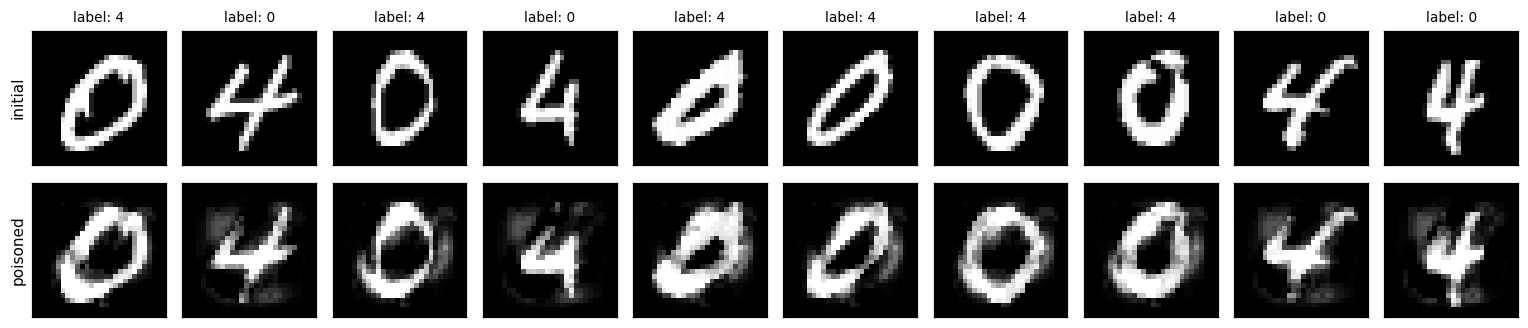

In [9]:
n_pm = 10
attack_m = BilevelPoisoningLogisticRegression(C=Cm, lb=0.0, ub=1.0, step_size=2.0, max_iter=200,
                                              tol=1e-8, random_seed=0, store_path=True)
t0 = time.time()
res_m = attack_m.run(xm_tr, ym_tr, xm_val, ym_val, n_points=n_pm)
print(f"attack time {time.time() - t0:.1f}s, {len(res_m.history['objective']) - 1} iterations")

x0m = res_m.history["x_poison"][0]
flip_m = LogisticRegression(784, C=Cm).fit(torch.cat([xm_tr, x0m]), torch.cat([ym_tr, res_m.y_poison]))
print(f"test accuracy  clean: {accuracy(clean_m, xm_ts, ym_ts):.4f} | "
      f"label flip: {accuracy(flip_m, xm_ts, ym_ts):.4f} | "
      f"bilevel poisoning: {accuracy(res_m.model, xm_ts, ym_ts):.4f}")

fig, axs = plt.subplots(2, n_pm, figsize=(1.4 * n_pm, 3.2))
for i in range(n_pm):
    lab = digits[0] if res_m.y_poison[i] == 1 else digits[1]
    axs[0, i].imshow(x0m[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axs[1, i].imshow(res_m.x_poison[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axs[0, i].set_title(f"label: {lab}", fontsize=9)
    for a in axs[:, i]: a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_ylabel("initial"); axs[1, 0].set_ylabel("poisoned")
plt.tight_layout()

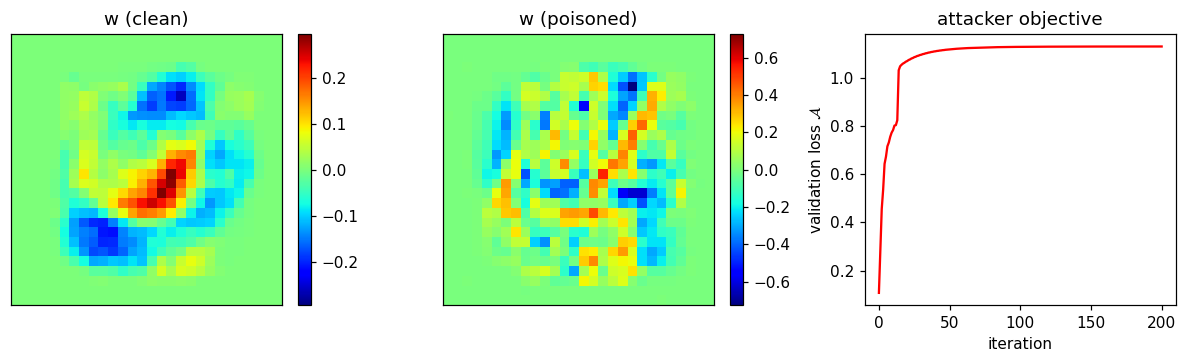

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, m, t in [(axs[0], clean_m, "w (clean)"), (axs[1], res_m.model, "w (poisoned)")]:
    w_img = m.weight.detach().reshape(28, 28)
    v = w_img.abs().max()
    im = ax.imshow(w_img, cmap=CMAP, vmin=-v, vmax=v); ax.set_title(t)
    ax.set_xticks([]); ax.set_yticks([]); plt.colorbar(im, ax=ax, fraction=0.046)
axs[2].plot(res_m.history["objective"], "r-"); axs[2].set_xlabel("iteration")
axs[2].set_ylabel("validation loss $\\mathcal{A}$"); axs[2].set_title("attacker objective")
plt.tight_layout()

### Test accuracy vs. fraction of poisoning points (MNIST 4 vs 0)

56.4s


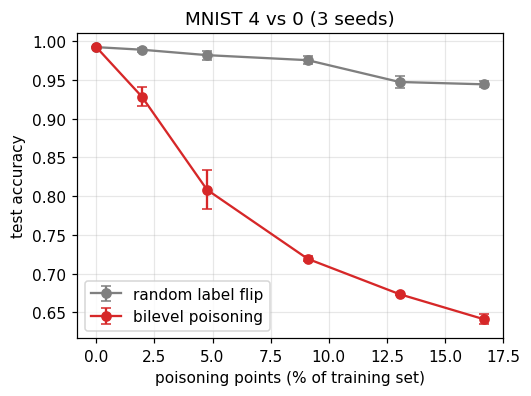

In [11]:
n_points_m = [0, 2, 5, 10, 15, 20]
t0 = time.time()
acc_atk_m, acc_flip_m = curve(xm_tr, ym_tr, xm_val, ym_val, xm_ts, ym_ts, n_points_m, seeds=range(3),
                              C=Cm, lb=0.0, ub=1.0, step_size=2.0, max_iter=100, tol=1e-8)
print(f"{time.time() - t0:.1f}s")
fig, ax = plt.subplots(figsize=(5, 3.6))
plot_curve(ax, n_points_m, len(xm_tr), acc_atk_m, acc_flip_m, "MNIST 4 vs 0 (3 seeds)")

## Notes and next steps

* The inner problem is solved with Newton's method in float64 to machine precision. This is required: the implicit
  function theorem assumes $\nabla_{\boldsymbol\theta}\mathcal L=\mathbf 0$, and an approximate solver (e.g. a few SGD
  epochs) gives a biased hypergradient.
* Cost per iteration: one warm-started retraining plus one $(d+1)\times(d+1)$ solve, whatever the number of points.
  For high-dimensional inputs, replace `torch.linalg.solve` with conjugate gradient on Hessian-vector products
  (`implicit_hypergradient` is where to plug that in).
* **SVM**: the hinge loss is not twice differentiable, so the generic autograd path does not apply directly. The
  ICML'12 / secml approach differentiates the KKT conditions restricted to the margin support vectors (the Hessian
  becomes the kernel matrix of margin SVs bordered by the bias row). That needs a torch SVM solver that returns the
  dual variables (e.g. a small QP or SMO solver), and is the natural next step.